# Chapitre 4 - Cours 2 : Suivi d'instructions, coût et latence

Ce notebook couvre la seconde moitié de la section *Evaluation Criteria* : la capacité à
**suivre des instructions** et le couple **coût / latence**. Plan :

1. distinguer capacité métier et suivi d'instructions (section *Instruction-Following Capability*) ;
2. des contraintes vérifiables par programme, à la IFEval (section *Instruction-following criteria*) ;
3. un banc d'essai maison : Qwen 0.5B contre Qwen 1.5B ;
4. au-delà du format : listes de critères oui/non à la INFOBench ;
5. le jeu de rôle (section *Roleplaying*) ;
6. l'anatomie de la latence : TTFT, TPOT, débit (section *Cost and Latency*) ;
7. ce qui fait varier la latence : longueur du prompt, taille de lot, percentiles ;
8. du débit au coût, et une grille de critères avec exigences dures.

Toutes les mesures de latence sont faites **pour de vrai** sur le GPU de la machine
(RTX 5070 Laptop, 8 Go). Ce GPU est partagé avec d'autres processus : les valeurs absolues
peuvent varier d'une exécution à l'autre, mais les tendances sont robustes.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # modèles déjà en cache : pas d'appel réseau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 90)
llm.seed_everything(0)

## 1. Savoir faire ou savoir obéir ? (section *Instruction-Following Capability*)

**Le problème.** On demande à un modèle d'étiqueter le sentiment de messages par POSITIF,
NEGATIF ou NEUTRE. Il comprend le sentiment, mais répond « Le sentiment est plutôt
joyeux ! ». La **capacité métier** est là, le **suivi d'instructions** non, et l'application
en aval, qui attend exactement une des trois étiquettes, casse. Le suivi d'instructions
est essentiel pour toute sortie structurée (JSON, expression régulière), mais va au-delà :
« n'utilise que des mots de quatre lettres au plus » (l'exemple d'Ello, qui génère des
histoires avec le vocabulaire d'un enfant) n'est pas structuré, mais reste une contrainte.

Mesurons les deux séparément sur Qwen 0.5B : (a) la **conformité** (la sortie est-elle
exactement une étiquette ?) et (b) l'**exactitude** après une analyse tolérante (on cherche
l'étiquette n'importe où dans la réponse).

In [2]:
messages = [
    ("Je viens de recevoir ma commande, tout est parfait, merci !", "POSITIF"),
    ("Le colis est arrivé cassé et personne ne répond au téléphone.", "NEGATIF"),
    ("La réunion est déplacée à jeudi 14 h.", "NEUTRE"),
    ("Franchement, le meilleur restaurant du quartier.", "POSITIF"),
    ("Encore une panne de réseau, c'est insupportable.", "NEGATIF"),
    ("Le magasin ouvre à 9 heures le samedi.", "NEUTRE"),
    ("Service rapide et personnel adorable.", "POSITIF"),
    ("Je regrette vraiment cet achat, quelle déception.", "NEGATIF"),
    ("Le train de 8 h 12 part du quai 3.", "NEUTRE"),
    ("Une application claire et agréable à utiliser.", "POSITIF"),
]
consigne = "Quel est le sentiment de ce message ? Réponds par POSITIF, NEGATIF ou NEUTRE.\nMessage : "
outs = c4.chat_batch([consigne + m for m, _ in messages], llm.SMALL, max_new_tokens=30)

def tolerant(o):
    o_up = o.upper().replace("NÉGATIF", "NEGATIF")
    found = [l for l in ["POSITIF", "NEGATIF", "NEUTRE"] if l in o_up]
    return found[0] if len(found) == 1 else None

sent = pd.DataFrame(dict(message=[m for m, _ in messages], attendu=[g for _, g in messages], sortie=outs))
sent["conforme"] = sent.sortie.str.strip().str.strip(".").isin(["POSITIF", "NEGATIF", "NEUTRE"])
sent["exact (tolérant)"] = [tolerant(o) == g for o, g in zip(sent.sortie, sent.attendu)]
print(f"conformité stricte : {sent.conforme.mean():.0%}   exactitude tolérante : {sent['exact (tolérant)'].mean():.0%}")
print("étiquettes produites :", sent.sortie.str.strip().value_counts().to_dict())
sent[["message", "attendu", "sortie", "conforme"]]

conformité stricte : 100%   exactitude tolérante : 40%
étiquettes produites : {'POSITIF': 10}


,message,attendu,sortie,conforme
0,"Je viens de recevoir ma commande, tout est parfait, merci !",POSITIF,POSITIF,True
1,Le colis est arrivé cassé et personne ne répond au téléphone.,NEGATIF,POSITIF,True
2,La réunion est déplacée à jeudi 14 h.,NEUTRE,POSITIF,True
3,"Franchement, le meilleur restaurant du quartier.",POSITIF,POSITIF,True
4,"Encore une panne de réseau, c'est insupportable.",NEGATIF,POSITIF,True
5,Le magasin ouvre à 9 heures le samedi.,NEUTRE,POSITIF,True
6,Service rapide et personnel adorable.,POSITIF,POSITIF,True
7,"Je regrette vraiment cet achat, quelle déception.",NEGATIF,POSITIF,True
8,Le train de 8 h 12 part du quai 3.,NEUTRE,POSITIF,True
9,Une application claire et agréable à utiliser.,POSITIF,POSITIF,True


Les deux nombres racontent deux histoires différentes, et les deux échecs existent :

- **conformité faible, exactitude tolérante bonne** : le modèle « sait » mais n'obéit pas au
  format ; le remède est du côté du prompt, du décodage contraint (chapitre 2) ou du
  post-traitement, pas forcément d'un modèle plus gros ;
- **conformité parfaite, exactitude faible** : le modèle obéit au format mais répond mal.
  C'est ce qui arrive ici (relire le tableau) : Qwen 0.5B répond presque toujours la même
  étiquette, la première citée dans la consigne. Une métrique de format seule afficherait
  100 % et masquerait un classifieur inutile. Le livre souligne la difficulté symétrique : si un modèle échoue à
écrire un poème *lục bát*, est-ce parce qu'il ne connaît pas cette forme, ou parce qu'il n'a
pas compris la consigne ? Et une mauvaise performance peut venir d'une **mauvaise
instruction** autant que d'un mauvais modèle.

> **À retenir.** Mesurez séparément la capacité métier (exactitude avec une analyse
> tolérante) et le suivi d'instructions (conformité stricte au format). Les deux échecs
> n'appellent pas les mêmes remèdes.

## 2. Des contraintes vérifiables par programme (section *Instruction-following criteria*)

**L'idée d'IFEval** (Zhou et al., 2023, Google) : ne retenir que des instructions dont le
respect se **vérifie par un programme**, sans juge humain ni IA. « Utilise le mot
éphémère » se vérifie par une recherche de chaîne ; « au plus 50 mots » par un comptage.
IFEval en définit 25 types, répartis en groupes (mots-clés, langue, longueur, contenu
détectable, format détectable). Le module du chapitre en implémente 19, avec leur texte en
français et leur vérificateur :

In [3]:
types = pd.DataFrame([(c4.INSTRUCTION_GROUPS[k], k, txt) for k, (txt, _) in c4.INSTRUCTION_TYPES.items()],
                     columns=["groupe", "type", "consigne (gabarit)"]).sort_values(["groupe", "type"])
types.reset_index(drop=True)

,groupe,type,consigne (gabarit)
0,casse,majuscules,Toute ta réponse doit être écrite EN MAJUSCULES.
1,casse,minuscules,"Toute ta réponse doit être écrite en minuscules, sans aucune majuscule."
2,contenu,emplacements,"Ta réponse doit contenir au moins {n} emplacements entre crochets, comme [adresse]."
3,contenu,fin_phrase,Termine ta réponse exactement par la phrase « {phrase} ».
4,contenu,post_scriptum,"À la fin de ta réponse, ajoute un post-scriptum commençant par {marker}"
5,format,choix_parmi,Réponds uniquement par l'une des options suivantes : {options}.
6,format,json,Toute ta réponse doit être au format JSON.
7,format,puces,"Ta réponse doit contenir exactement {n} puces markdown, comme : * un point."
8,format,surlignage,"Mets en valeur au moins {n} passages en markdown, comme *passage important*."
9,format,titre,"Ta réponse doit avoir un titre entre doubles chevrons, comme <<titre>>."


**Quatre scores.** Une tâche peut porter plusieurs contraintes. IFEval rapporte :

- le score **au niveau du prompt** : fraction des tâches dont *toutes* les contraintes sont
  respectées ;
- le score **au niveau de l'instruction** : fraction des contraintes respectées ;
- chacun en version **stricte** (la réponse brute) et **souple** (*loose*) : la contrainte est
  jugée respectée si l'une de 8 variantes de la réponse la satisfait (sans la première
  ligne, sans la dernière, sans les deux, avec ou sans astérisques markdown). La version
  souple pardonne le « Voici ma réponse : » initial ou la mise en gras parasite.

Si une tâche $t$ porte les contraintes $c_{t,1},\dots,c_{t,m_t}$ de verdicts $v_{t,j}\in\{0,1\}$ :
$$\text{prompt} = \frac{1}{T}\sum_t \prod_j v_{t,j}, \qquad
  \text{instruction} = \frac{\sum_t\sum_j v_{t,j}}{\sum_t m_t}.$$
Le score au niveau du prompt est toujours inférieur ou égal : il faut tout réussir.

In [4]:
demo = c4.IFTask("Liste trois fruits rouges.", [c4.Instruction("puces", dict(n=3)), c4.Instruction("minuscules")])
reponses = {
    "parfaite": "* fraise\n* framboise\n* cerise",
    "préambule": "Voici trois fruits :\n* fraise\n* framboise\n* cerise",
    "gras": "* **fraise**\n* framboise\n* cerise",
    "quatre puces": "* fraise\n* framboise\n* cerise\n* groseille",
}
print("Tâche :", demo.prompt)
pd.concat({k: c4.evaluate_ifeval([demo], [v]).set_index("type")[["strict", "souple"]] for k, v in reponses.items()}).unstack()

Tâche : Liste trois fruits rouges. Ta réponse doit contenir exactement 3 puces markdown, comme : * un point. Toute ta réponse doit être écrite en minuscules, sans aucune majuscule.


strict            souple           
type          puces minuscules  puces minuscules
parfaite       True       True   True       True
préambule      True      False   True       True
gras           True       True   True       True
quatre puces  False       True   True       True

La réponse avec préambule échoue en strict sur les minuscules (« Voici » a une majuscule)
mais passe en souple (on retire la première ligne). Les quatre puces échouent dans les deux
cas : c'est une vraie violation.

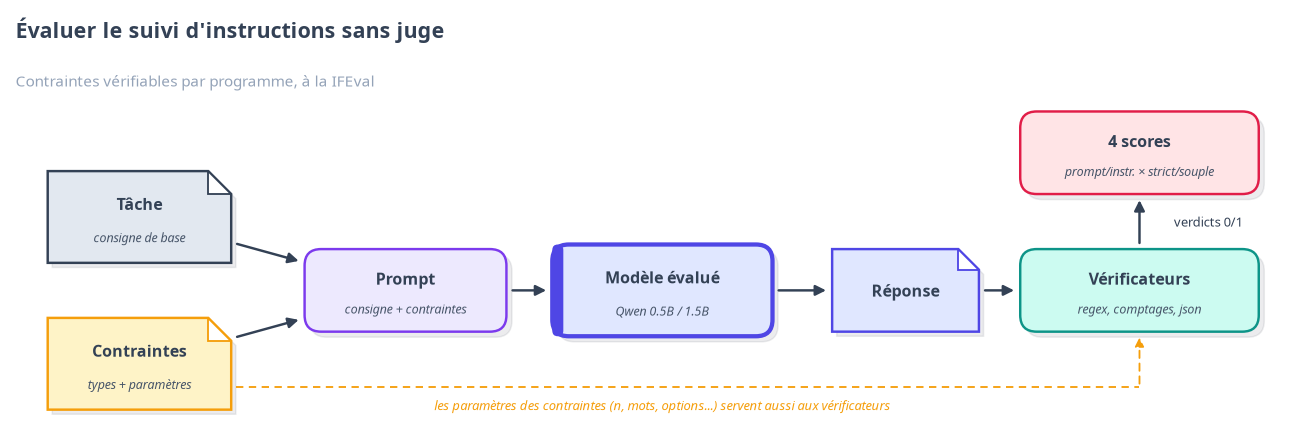

In [5]:
d = Diagram(14, 3.6, title="Évaluer le suivi d'instructions sans juge",
            subtitle="Contraintes vérifiables par programme, à la IFEval")
d.box("task", 1.4, 2.3, "Tâche", sub="consigne de base", color=SLATE, kind="doc", w=2.0, h=1.0)
d.box("cons", 1.4, 0.7, "Contraintes", sub="types + paramètres", color=AMBER, kind="doc", w=2.0, h=1.0)
d.box("prompt", 4.3, 1.5, "Prompt", sub="consigne + contraintes", color=VIOLET, w=2.2)
d.box("llm", 7.1, 1.5, "Modèle évalué", sub="Qwen 0.5B / 1.5B", color=INDIGO, kind="model", w=2.4, h=1.0)
d.box("resp", 9.75, 1.5, "Réponse", color=INDIGO, kind="doc", w=1.6, h=0.9)
d.box("chk", 12.3, 1.5, "Vérificateurs", sub="regex, comptages, json", color=TEAL, w=2.6)
d.box("score", 12.3, 3.0, "4 scores", sub="prompt/instr. × strict/souple", color=ROSE, w=2.6)
d.arrow("task", "prompt"); d.arrow("cons", "prompt")
d.arrow("prompt", "llm"); d.arrow("llm", "resp"); d.arrow("resp", "chk")
d.line([(2.45, 0.45), (12.3, 0.45), (12.3, 1.02)], color=AMBER, style="dashed")
d.note(7.1, 0.25, "les paramètres des contraintes (n, mots, options...) servent aussi aux vérificateurs", color=AMBER, fontsize=8.5)
d.arrow("chk", "score", "verdicts 0/1", label_offset=(0.75, 0))
d.show()

> **À retenir.** Une contrainte vérifiable par programme donne une évaluation exacte,
> reproductible et gratuite. IFEval rapporte quatre scores : prompt ou instruction, strict
> ou souple ; l'écart strict/souple mesure les « fautes de forme » pardonnables.

## 3. Un banc d'essai maison : Qwen 0.5B contre Qwen 1.5B

Le livre insiste : les benchmarks publics ne contiennent pas *vos* instructions ; il faut
construire le sien. Le module propose 24 tâches en français, portant 1 à 3 contraintes
chacune (34 contraintes). On génère de façon gloutonne (température 0) avec les deux modèles.

In [6]:
tasks = c4.IF_TASKS
prompts = [t.prompt for t in tasks]
gens = {"Qwen 0.5B": c4.chat_batch(prompts, llm.SMALL, max_new_tokens=220)}
llm.free_gpu()   # GPU partagé : un seul modèle en mémoire à la fois
gens["Qwen 1.5B"] = c4.chat_batch(prompts, llm.MEDIUM, max_new_tokens=220)
evals = {k: c4.evaluate_ifeval(tasks, v) for k, v in gens.items()}
scores = pd.DataFrame({k: c4.ifeval_summary(v) for k, v in evals.items()})
(scores * 100).round(1)

,Qwen 0.5B,Qwen 1.5B
prompt strict,29.2,50.0
prompt souple,29.2,54.2
instruction strict,43.8,62.5
instruction souple,43.8,65.6


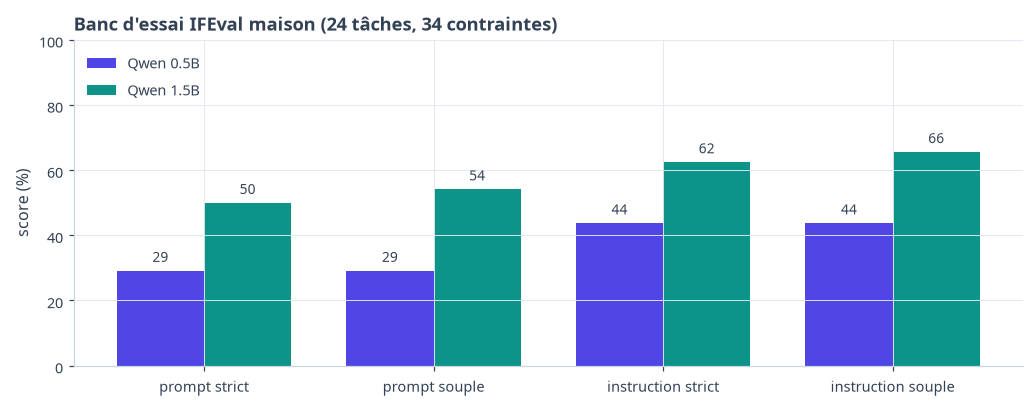

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(scores))
for j, (col, c) in enumerate(zip(scores.columns, [INDIGO, TEAL])):
    ax.bar(x + (j - 0.5) * 0.38, scores[col] * 100, width=0.38, color=c, label=col)
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, scores.index); ax.set_ylabel("score (%)"); ax.set_ylim(0, 100)
ax.legend(loc="upper left"); ax.set_title("Banc d'essai IFEval maison (24 tâches, 34 contraintes)")
plt.tight_layout(); plt.show()

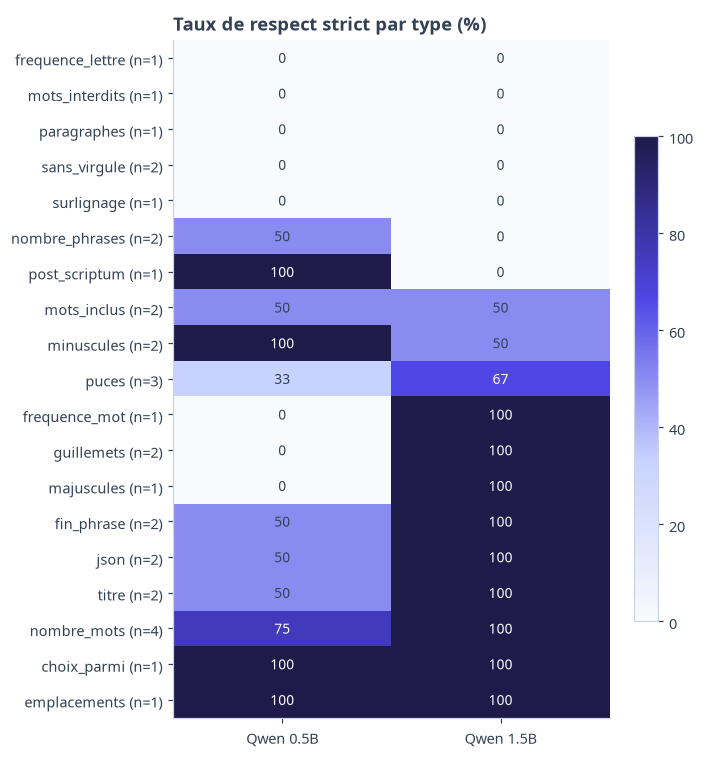

In [8]:
by_type = pd.DataFrame({k: v.groupby("type")["strict"].mean() for k, v in evals.items()})
by_type["n"] = evals["Qwen 0.5B"].groupby("type").size()
by_type = by_type.sort_values(["Qwen 1.5B", "Qwen 0.5B"])
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(by_type[["Qwen 0.5B", "Qwen 1.5B"]].values * 100, cmap="aie_seq", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(by_type)), [f"{t} (n={n})" for t, n in zip(by_type.index, by_type.n)])
ax.set_xticks([0, 1], ["Qwen 0.5B", "Qwen 1.5B"]); ax.grid(False)
for i in range(len(by_type)):
    for j, col in enumerate(["Qwen 0.5B", "Qwen 1.5B"]):
        v = by_type[col].iloc[i] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 60 else SLATE, fontsize=9)
ax.set_title("Taux de respect strict par type (%)")
plt.colorbar(im, ax=ax, fraction=0.05)
plt.tight_layout(); plt.show()

Quelques constats typiques des petits modèles (à relire sur la sortie ci-dessus, qui peut
légèrement varier) : les contraintes « naturelles » (JSON, emplacements entre crochets,
choix parmi des options) passent bien ; les contraintes qui vont **contre les habitudes de
génération** (ne pas utiliser de virgule, tout écrire en majuscules, éviter un mot
central du sujet comme « eau » pour parler d'un nuage, un nombre exact de puces) échouent
souvent. Chaque type n'a que 1 à 4 occurrences : les scores par type sont très bruités.
Regardons quelques échecs du petit modèle.

In [9]:
ev = evals["Qwen 0.5B"]
fails = ev[~ev.strict].drop_duplicates("tache").head(4)
for _, r in fails.iterrows():
    t = tasks[r.tache]
    print(f"[{r.type}] {t.prompt}\n  -> {gens['Qwen 0.5B'][r.tache][:160]!r}\n")

[nombre_mots] Décris les bienfaits du vélo en ville. Réponds en au plus 50 mots.
  -> "Le vélo en ville offre plusieurs avantages pour la santé et l'environnement :\n\n1. Économie de carburant : Le vélo est moins polluant que le véhicule automobile."

[puces] Donne des conseils pour bien dormir. Ta réponse doit contenir exactement 3 puces markdown, comme : * un point.
  -> "* **1.** Établissez une routine de sommeil régulière et précoce. Cela peut inclure la consommation d'alcool à moins que vous ne soyez en mesure de faire autreme"

[titre] Présente brièvement la ville de Lyon. Ta réponse doit avoir un titre entre doubles chevrons, comme <<titre>>. Réponds en au plus 3 phrases.
  -> "Lyon est une ville italienne située dans le sud-est de France, sur l'île de Provence. Elle est connue pour ses rues étroites, ses églises historiques et ses qua"

[mots_interdits] Explique ce qu'est un nuage. N'utilise aucun des mots suivants : « eau », « pluie ».
  -> "Un nuage est une forme céleste qui 

> **À retenir.** Un banc d'essai de suivi d'instructions se construit en quelques dizaines
> de lignes. Il révèle des faiblesses très spécifiques (contraintes « contre nature ») qui
> n'apparaissent pas dans un score global, et le modèle plus gros n'est pas meilleur partout.

## 4. Au-delà du format : critères oui/non à la INFOBench (section *Instruction-following criteria*)

INFOBench (Qin et al., 2024) élargit la notion : contraintes de **contenu** (« ne parle que
du climat »), de **langue** (« anglais victorien »), de **style** (« ton respectueux »). Ces
contraintes ne se vérifient pas par une regex. L'astuce : décomposer chaque instruction en
une liste de **questions oui/non**, auxquelles un humain ou une IA juge répond. Le score
d'une sortie est la fraction des critères satisfaits ; le score global est le nombre total de
critères satisfaits divisé par le nombre total de critères.

On reprend l'exemple du livre (un questionnaire pour les clients d'un hôtel) et on fait
juger les deux modèles par Qwen 1.5B, en lisant la probabilité de la réponse « Oui » contre
« Non » (juge à logprobs, donc déterministe, comme à température 0).

In [10]:
instr = "Rédige un court questionnaire pour aider les clients d'un hôtel à écrire leur avis."
criteres = ["Le texte généré est-il un questionnaire ?",
            "Le questionnaire s'adresse-t-il à des clients d'hôtel ?",
            "Le questionnaire aide-t-il à rédiger un avis sur l'hôtel ?"]
llm.free_gpu()
reps = {"Qwen 0.5B": c4.chat_batch([instr], llm.SMALL, max_new_tokens=160)[0]}
llm.free_gpu()
reps["Qwen 1.5B"] = c4.chat_batch([instr], llm.MEDIUM, max_new_tokens=160)[0]
reps["hors sujet (témoin)"] = "La tour Eiffel mesure 330 mètres et a été construite pour l'Exposition universelle de 1889."
rows = []
for name, rep in reps.items():
    for crit in criteres:
        q = (f"Instruction : {instr}\n\nTexte produit :\n{rep}\n\nQuestion : {crit}\n"
             "Réponds uniquement par Oui ou par Non.")
        rows.append(dict(sortie=name, critère=crit, p_oui=c4.yes_probability(q, llm.MEDIUM)))
info = pd.DataFrame(rows)
info["satisfait"] = info.p_oui > 0.5
tab = info.pivot(index="critère", columns="sortie", values="p_oui").round(2)
tab.loc["score INFOBench"] = info.groupby("sortie")["satisfait"].mean()
llm.free_gpu()
tab

sortie,Qwen 0.5B,Qwen 1.5B,hors sujet (témoin)
critère,,,
Le questionnaire aide-t-il à rédiger un avis sur l'hôtel ?,0.88,0.80,0.29
Le questionnaire s'adresse-t-il à des clients d'hôtel ?,0.97,0.90,0.44
Le texte généré est-il un questionnaire ?,0.73,0.78,0.02
score INFOBench,1.00,1.00,0.00


Le témoin hors sujet doit échouer sur les trois critères : c'est un **contrôle de santé**
du juge, à prévoir systématiquement. Les auteurs d'INFOBench trouvent GPT-4 moins précis
que des experts humains mais plus précis que des annotateurs recrutés sur Mechanical Turk ;
un juge de 1,5 milliard de paramètres est évidemment bien moins fiable (cours 4 : évaluer
l'évaluateur).

> **À retenir.** Quand une contrainte n'est pas vérifiable par programme, décomposez-la en
> critères oui/non explicites : la tâche du juge devient plus simple et plus reproductible.

## 5. Le jeu de rôle (section *Roleplaying*)

Le jeu de rôle est l'un des usages les plus fréquents (8e catégorie dans l'analyse par
LMSYS d'un million de conversations) : PNJ de jeux vidéo, compagnons, assistants d'écriture,
ou simple technique de prompt. Il faut vérifier que le modèle **reste dans son
personnage**, en style comme en connaissances. Le livre suggère des **heuristiques** quand le
rôle s'y prête : pour un personnage peu bavard, la longueur moyenne des réponses.

Expérience : un vieux gardien de phare laconique, avec ou sans prompt système de
personnage. On mesure (1) la longueur des réponses, (2) une « sortie de rôle » détectée
par mots-clés (« assistant », « IA », « modèle de langage »).

In [11]:
persona = ("Tu es Yvon, un vieux gardien de phare breton, bourru et laconique. "
           "Tu réponds toujours en une seule phrase très courte, sans jamais dire que tu es une IA.")
questions = ["Comment allez-vous aujourd'hui ?", "Que pensez-vous de la tempête d'hier ?",
             "Pouvez-vous m'expliquer comment fonctionne un phare ?", "Quel est votre plat préféré ?",
             "Êtes-vous une intelligence artificielle ?", "Racontez-moi votre plus beau souvenir.",
             "Quel temps fera-t-il demain ?", "Pourquoi vivez-vous seul ici ?"]
role = {"sans personnage": c4.chat_batch(questions, llm.SMALL, max_new_tokens=120),
        "avec personnage": c4.chat_batch(questions, llm.SMALL, max_new_tokens=120, system=persona)}
breaks = ["assistant", "intelligence artificielle", "une ia", "modèle de langage", "language model"]
rp = pd.DataFrame([dict(condition=k, question=q, mots=c4.count_words(r),
                        sortie_de_role=any(b in r.lower() for b in breaks), reponse=r[:80])
                   for k, v in role.items() for q, r in zip(questions, v)])
rp.groupby("condition")[["mots", "sortie_de_role"]].mean().round(2)

,mots,sortie_de_role
condition,,
avec personnage,18.88,0.12
sans personnage,44.25,0.38


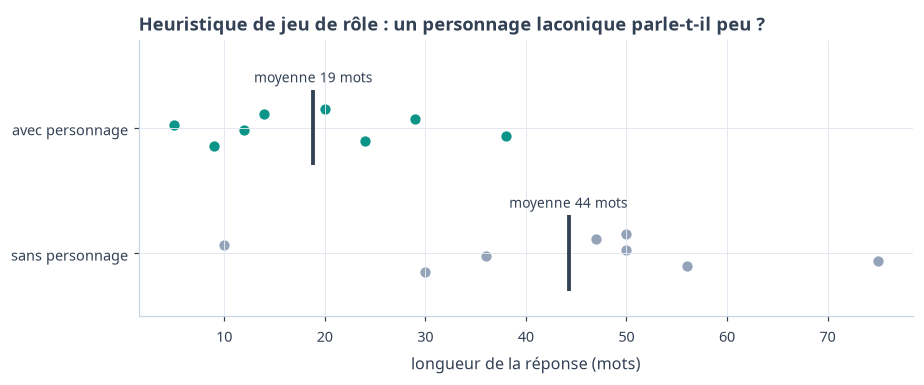

,question,reponse,sortie_de_role
8,Comment allez-vous aujourd'hui ?,"Bien sûr, comment puis-je vous aider aujourd'hui ?",False
9,Que pensez-vous de la tempête d'hier ?,Je ne peux pas évaluer les prédictions météorologiques ou les prévisions atmosph,False
10,Pouvez-vous m'expliquer comment fonctionne un phare ?,Un phare est un appareil qui transmet des informations à l'aide d'un signal sono,False
11,Quel est votre plat préféré ?,"Un pain à la viande, bien que je ne le boive pas.",False
12,Êtes-vous une intelligence artificielle ?,"Oui, je suis une IA.",True


In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for i, (k, c) in enumerate([("sans personnage", GRAY), ("avec personnage", TEAL)]):
    v = rp.loc[rp.condition == k, "mots"]
    ax.scatter(v, np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), color=c, s=60, edgecolor="white")
    ax.vlines(v.mean(), i - 0.3, i + 0.3, color=SLATE, lw=2.5)
    ax.text(v.mean(), i + 0.36, f"moyenne {v.mean():.0f} mots", ha="center", fontsize=9)
ax.set_yticks([0, 1], ["sans personnage", "avec personnage"]); ax.set_ylim(-0.5, 1.7)
ax.set_xlabel("longueur de la réponse (mots)")
ax.set_title("Heuristique de jeu de rôle : un personnage laconique parle-t-il peu ?")
plt.tight_layout(); plt.show()
rp.loc[rp.condition == "avec personnage", ["question", "reponse", "sortie_de_role"]].head(5)

Le prompt de personnage raccourcit fortement les réponses : l'heuristique de longueur le
capte immédiatement. Le personnage est pourtant mal tenu par un modèle de 0,5 milliard de
paramètres : le style reste celui d'un assistant (« comment puis-je vous aider ? ») et, à la
question directe, il peut avouer être une IA malgré la consigne ; d'où la colonne
`sortie_de_role`, qui n'est pas nulle. Elle ne dit rien, en revanche, du **style** ni des **connaissances**
(Yvon ne devrait pas expliquer la mécanique quantique, c'est la vérification de « connaissance
négative » qui évite qu'un PNJ divulgue la fin d'un jeu) : pour cela on recourt à une IA juge
avec un prompt dédié, comme celui de RoleLLM que cite le livre.

> **À retenir.** Évaluez un jeu de rôle sur le style et sur les connaissances ; des
> heuristiques simples (longueur, mots interdits) couvrent une partie du style, une IA juge
> le reste.

## 6. L'anatomie de la latence (section *Cost and Latency*)

Un modèle excellent mais trop lent ou trop cher est inutilisable. Le livre liste plusieurs
métriques de latence ; précisons-les. Un modèle autorégressif traite une requête en deux
phases :

- le **préremplissage** (*prefill*) : tout le prompt passe en une seule passe parallèle et
  produit le premier token ; sa durée est le **TTFT** (*time to first token*) ;
- le **décodage** (*decode*) : chaque token suivant demande une passe ; l'intervalle entre
  deux tokens est l'**ITL** (*inter-token latency*, ou *time between tokens*), et sa moyenne
  le **TPOT** (*time per output token*).

Pour une réponse de $n$ tokens :
$$\text{latence totale} = \text{TTFT} + (n-1)\,\text{TPOT}, \qquad
  \text{débit par requête} = \frac{n}{\text{latence totale}}.$$

Le TTFT conditionne l'impression de réactivité (en streaming, l'utilisateur voit le texte
arriver dès le premier token) ; le TPOT doit surtout rester plus rapide que la lecture
humaine (environ 4 à 5 mots par seconde, soit 6 à 7 tokens par seconde, donc un TPOT
inférieur à environ 150 ms).

In [13]:
tok, _ = llm.load(llm.SMALL)
texte_long = (" ".join(c4.FACT_CONTEXT for _ in range(400)))
all_ids = tok(texte_long)["input_ids"]
for _ in range(3):  # échauffement (compilation des noyaux CUDA, allocation du cache)
    c4.measure_latency(all_ids[:256], llm.SMALL, max_new_tokens=16)
r = c4.measure_latency(all_ids[:512], llm.SMALL, max_new_tokens=128)
print(f"prompt {r.n_prompt} tokens, {r.n_output} tokens générés")
print(f"TTFT = {r.ttft*1e3:.1f} ms | TPOT = {r.tpot*1e3:.1f} ms | total = {r.total*1e3:.0f} ms "
      f"| débit = {r.throughput:.0f} tokens/s")

prompt 512 tokens, 128 tokens générés
TTFT = 35.5 ms | TPOT = 10.7 ms | total = 1389 ms | débit = 92 tokens/s


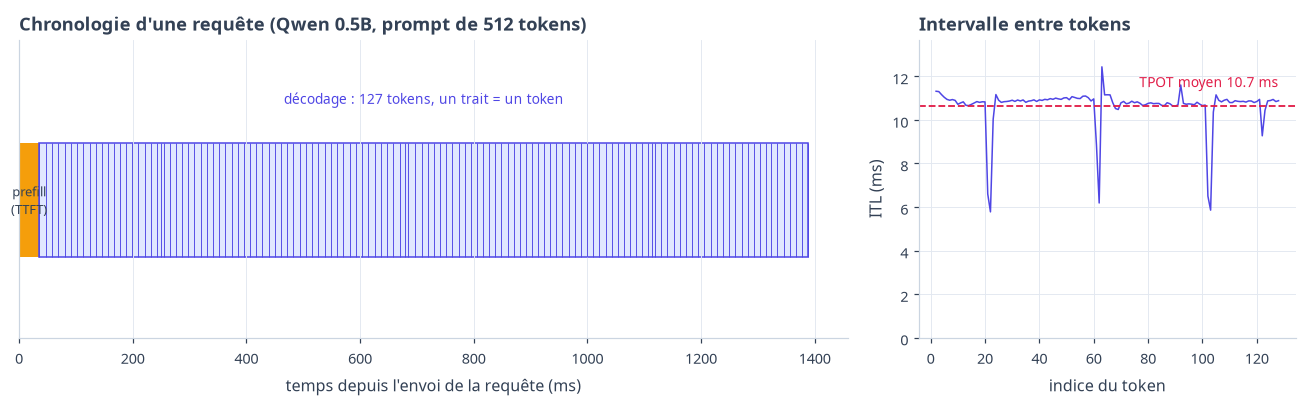

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[2.2, 1]))
t_tokens = r.ttft + np.r_[0, np.cumsum(r.itl)]
ax = axes[0]
ax.barh(0, r.ttft * 1e3, color=AMBER, height=0.5)
ax.text(r.ttft * 1e3 / 2, 0, "prefill\n(TTFT)", ha="center", va="center", fontsize=8.5, color=SLATE)
ax.barh(0, (r.total - r.ttft) * 1e3, left=r.ttft * 1e3, color=LIGHT[INDIGO], height=0.5, edgecolor=INDIGO)
ax.vlines(t_tokens * 1e3, -0.25, 0.25, color=INDIGO, lw=0.6)
ax.text((r.ttft + r.total) / 2 * 1e3, 0.42, f"décodage : {r.n_output - 1} tokens, un trait = un token", ha="center",
        fontsize=9, color=INDIGO)
ax.set_yticks([]); ax.set_ylim(-0.6, 0.7); ax.set_xlabel("temps depuis l'envoi de la requête (ms)")
ax.set_title("Chronologie d'une requête (Qwen 0.5B, prompt de 512 tokens)")
ax = axes[1]
ax.plot(np.arange(2, r.n_output + 1), r.itl * 1e3, color=INDIGO, lw=1)
ax.axhline(r.tpot * 1e3, color=ROSE, ls="--", lw=1.2)
ax.text(r.n_output, r.tpot * 1e3 * 1.08, f"TPOT moyen {r.tpot*1e3:.1f} ms", ha="right", color=ROSE, fontsize=9)
ax.set_xlabel("indice du token"); ax.set_ylabel("ITL (ms)"); ax.set_ylim(0, max(r.itl.max() * 1e3 * 1.1, 1))
ax.set_title("Intervalle entre tokens")
finish(fig)

Le TTFT est ici du même ordre qu'un ou quelques pas de décodage : pour un petit modèle et
un prompt de 512 tokens, le préremplissage est rapide car parallèle. Le décodage, lui,
est **séquentiel** : chaque token attend le précédent. Les pics d'ITL éventuels viennent
du partage du GPU avec d'autres processus et du système (ramasse-miettes Python) ; c'est
pourquoi on rapporte des **percentiles** plutôt qu'une seule mesure.

> **À retenir.** Latence totale = TTFT + $(n-1)$ × TPOT. Le TTFT dépend surtout du prompt
> (préremplissage parallèle), le TPOT de la phase séquentielle de décodage ; le nombre de
> tokens générés est le premier levier sur la latence totale.

## 7. Ce qui fait varier la latence : prompt, lot, percentiles

**Longueur du prompt.** Le préremplissage traite $L$ tokens en parallèle ; son coût croît
avec $L$ (linéairement pour les couches denses, quadratiquement pour l'attention), mais
tant que le GPU n'est pas saturé, la croissance est sous-linéaire.

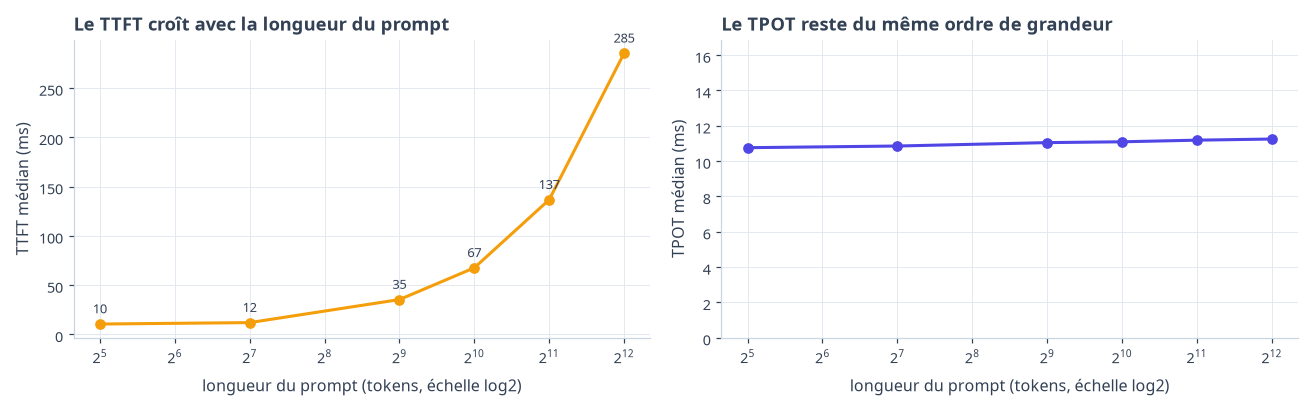

In [15]:
lengths = [32, 128, 512, 1024, 2048, 4096]
ttft_rows = []
for L in lengths:
    for rep in range(5):
        rr = c4.measure_latency(all_ids[:L], llm.SMALL, max_new_tokens=8)
        ttft_rows.append(dict(L=L, ttft=rr.ttft * 1e3, tpot=rr.tpot * 1e3))
ttft_df = pd.DataFrame(ttft_rows).groupby("L").median()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ttft_df.index, ttft_df.ttft, "o-", color=AMBER)
for L, v in ttft_df.ttft.items():
    axes[0].annotate(f"{v:.0f}", (L, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8.5)
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("longueur du prompt (tokens, échelle log2)")
axes[0].set_ylabel("TTFT médian (ms)"); axes[0].set_title("Le TTFT croît avec la longueur du prompt")
axes[1].plot(ttft_df.index, ttft_df.tpot, "o-", color=INDIGO)
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("longueur du prompt (tokens, échelle log2)")
axes[1].set_ylabel("TPOT médian (ms)"); axes[1].set_ylim(0, ttft_df.tpot.max() * 1.5)
axes[1].set_title("Le TPOT reste du même ordre de grandeur")
finish(fig)

**Taille de lot.** Un serveur regroupe les requêtes de plusieurs utilisateurs. Le décodage
d'un petit modèle est limité par la **bande passante mémoire** (il faut relire tous les poids
pour chaque pas), pas par le calcul : traiter 8 séquences en même temps coûte à peine plus
cher qu'une seule. Le **débit total** (tokens/s servis) augmente donc presque
proportionnellement au lot, tandis que la latence ressentie par chaque utilisateur (TPOT)
augmente peu, jusqu'à saturation.

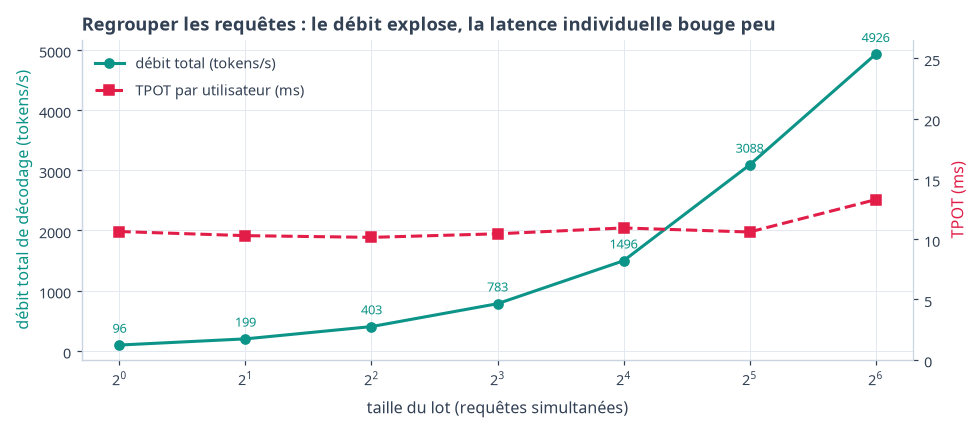

gain de débit entre B=1 et B=64 : x51.2 ; TPOT x1.2


In [16]:
batches = [1, 2, 4, 8, 16, 32, 64]
bt = []
for B in batches:
    meas = [c4.measure_latency(all_ids[:128], llm.SMALL, max_new_tokens=48, batch_size=B) for _ in range(3)]
    m = sorted(meas, key=lambda z: z.total)[1]                    # médiane des 3 essais
    bt.append(dict(B=B, tpot=m.tpot * 1e3, debit=m.n_output / (m.total - m.ttft)))
bt = pd.DataFrame(bt).set_index("B")

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(bt.index, bt.debit, "o-", color=TEAL, label="débit total (tokens/s)")
ax1.set_xscale("log", base=2); ax1.set_xlabel("taille du lot (requêtes simultanées)")
ax1.set_ylabel("débit total de décodage (tokens/s)", color=TEAL)
for B, v in bt.debit.items():
    ax1.annotate(f"{v:.0f}", (B, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color=TEAL)
ax2 = ax1.twinx()
ax2.plot(bt.index, bt.tpot, "s--", color=ROSE, label="TPOT par utilisateur (ms)")
ax2.set_ylabel("TPOT (ms)", color=ROSE); ax2.set_ylim(0, bt.tpot.max() * 2); ax2.grid(False)
ax2.spines["right"].set_visible(True)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Regrouper les requêtes : le débit explose, la latence individuelle bouge peu")
plt.tight_layout(); plt.show()
print(f"gain de débit entre B=1 et B={batches[-1]} : x{bt.debit.iloc[-1] / bt.debit.iloc[0]:.1f} ; "
      f"TPOT x{bt.tpot.iloc[-1] / bt.tpot.iloc[0]:.1f}")

Ce compromis débit / latence est au cœur de l'optimisation de l'inférence (chapitre 9).
Il explique aussi une phrase du livre : le coût par token d'un auto-hébergement **baisse**
avec le volume, parce qu'un GPU bien rempli sert beaucoup plus de tokens pour le même prix.

**Percentiles.** La latence varie d'une requête à l'autre (longueur de la réponse, charge
du serveur). Un contrat de service se formule en percentiles : « TTFT P90 < 200 ms » signifie
que 90 % des requêtes reçoivent leur premier token en moins de 200 ms. Simulons un trafic de
40 requêtes dont la longueur de réponse suit une loi log-normale (beaucoup de réponses
courtes, quelques très longues).

In [17]:
rng = np.random.default_rng(0)
n_out = np.clip(rng.lognormal(mean=np.log(60), sigma=0.7, size=40).astype(int), 5, 300)
n_in = rng.integers(50, 1500, size=40)
lat = [c4.measure_latency(all_ids[:li], llm.SMALL, max_new_tokens=int(no)) for li, no in zip(n_in, n_out)]
lat_df = pd.DataFrame(dict(n_in=n_in, n_out=n_out, ttft=[z.ttft * 1e3 for z in lat],
                           total=[z.total * 1e3 for z in lat], tpot=[z.tpot * 1e3 for z in lat]))
pct = lat_df[["ttft", "tpot", "total"]].quantile([0.5, 0.9, 0.99]).T
pct.columns = ["P50", "P90", "P99"]
pct.round(1)

,P50,P90,P99
ttft,51.9,80.4,89.1
tpot,10.4,10.8,10.9
total,641.9,1236.6,1652.6


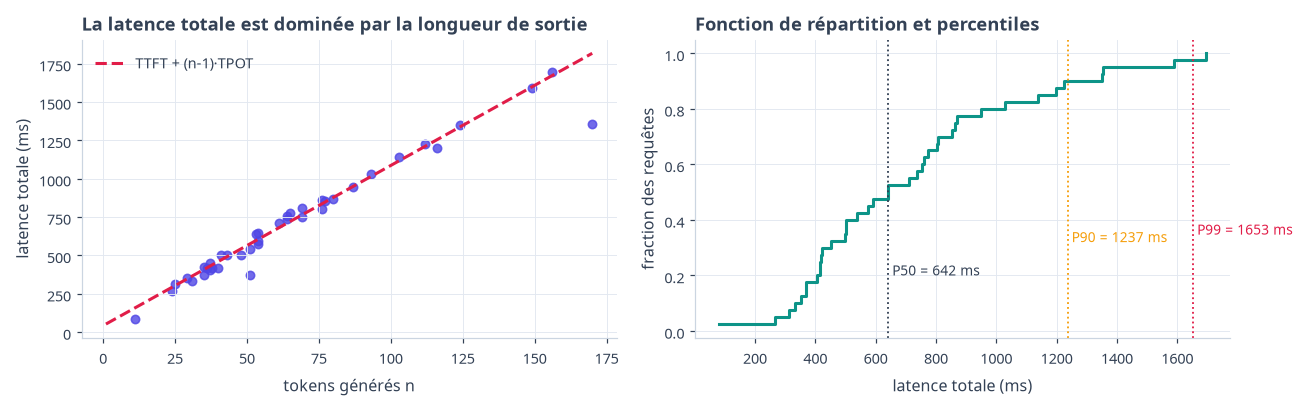

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.scatter(lat_df.n_out, lat_df.total, color=INDIGO, s=30, alpha=0.8)
tt, tp = lat_df.ttft.median(), lat_df.tpot.median()
xs = np.linspace(1, lat_df.n_out.max(), 100)
ax.plot(xs, c4.latency_model(xs, tt, tp), color=ROSE, ls="--", label=f"TTFT + (n-1)·TPOT")
ax.set_xlabel("tokens générés n"); ax.set_ylabel("latence totale (ms)"); ax.legend()
ax.set_title("La latence totale est dominée par la longueur de sortie")
ax = axes[1]
srt = np.sort(lat_df.total)
ax.plot(srt, np.arange(1, len(srt) + 1) / len(srt), color=TEAL, drawstyle="steps-post")
for q, c in [(0.5, SLATE), (0.9, AMBER), (0.99, ROSE)]:
    v = np.quantile(lat_df.total, q)
    ax.axvline(v, color=c, ls=":", lw=1.2)
    ax.text(v, 0.05 + q * 0.3, f" P{int(q*100)} = {v:.0f} ms", color=c, fontsize=9)
ax.set_xlabel("latence totale (ms)"); ax.set_ylabel("fraction des requêtes")
ax.set_title("Fonction de répartition et percentiles")
finish(fig)

Le modèle linéaire $\text{TTFT} + (n-1)\,\text{TPOT}$ explique l'essentiel de la variance :
pour réduire la latence ressentie, demander au modèle d'être concis ou fixer une condition
d'arrêt (chapitre 2) est souvent plus efficace que de changer de modèle. Le P99 est tiré par
les réponses les plus longues.

> **À retenir.** Rapportez la latence en percentiles (P50, P90, P99) et pour une métrique
> précise (TTFT, TPOT, latence totale). Le lot (*batching*) multiplie le débit d'un GPU pour
> un faible surcoût de latence individuelle.

## 8. Du débit au coût, et une grille de critères

**Avec une API**, on paie au token : pour une requête de $n_{in}$ tokens d'entrée et
$n_{out}$ de sortie aux prix $\pi_{in}, \pi_{out}$ (en $ par million de tokens),
$$\text{coût} = \frac{n_{in}\,\pi_{in} + n_{out}\,\pi_{out}}{10^6}.$$

**En auto-hébergement**, on paie le temps de GPU : si un GPU loué $h$ $/heure sert un débit
moyen $D$ tokens/s, le coût par million de tokens vaut
$$c = \frac{h}{3600\,D}\times 10^6.$$
Utilisons les débits que nous venons de **mesurer**, avec un prix de location fictif de
0,40 $/heure pour un GPU de cette classe.

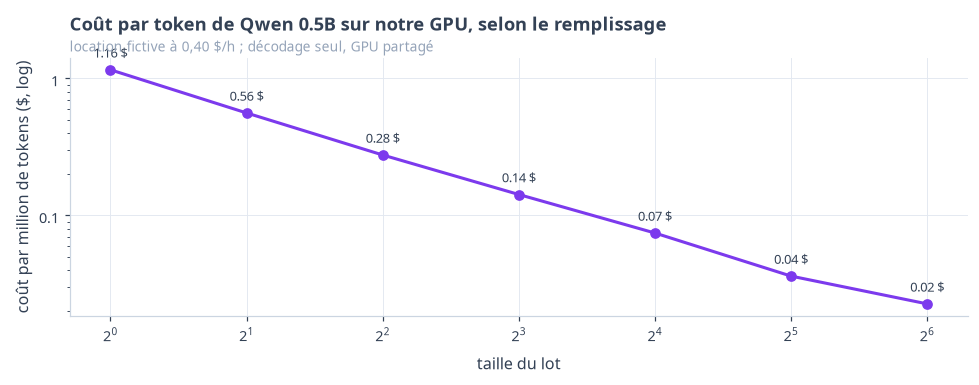

In [19]:
h = 0.40
cost = pd.DataFrame(dict(debit=bt.debit))
cost["$ / M tokens"] = h / (3600 * cost.debit) * 1e6
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(cost.index, cost["$ / M tokens"], "o-", color=VIOLET)
ax.set_xscale("log", base=2); ax.set_yscale("log")
from matplotlib.ticker import FuncFormatter
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
from matplotlib.ticker import NullFormatter
ax.yaxis.set_minor_formatter(NullFormatter())
for B, v in cost["$ / M tokens"].items():
    ax.annotate(f"{v:.2f} $", (B, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5)
ax.set_xlabel("taille du lot"); ax.set_ylabel("coût par million de tokens ($, log)")
ax.set_title("Coût par token de Qwen 0.5B sur notre GPU, selon le remplissage", pad=18)
subtitle(ax, "location fictive à 0,40 $/h ; décodage seul, GPU partagé")
plt.tight_layout(); plt.show()

Le coût par token chute d'un ordre de grandeur quand le GPU est bien rempli. C'est toute
la question « construire ou acheter » du cours 3 : une API a un coût par token constant,
l'auto-hébergement un coût par token qui dépend de l'utilisation.

**Une grille de critères.** Le livre propose (tableau 4-3) de résumer les critères dans un
tableau avec, pour chacun, une métrique, un benchmark, une **exigence dure** (éliminatoire)
et une valeur **idéale**. Remplissons-en une pour un assistant interne, et confrontons-la à
nos mesures sur Qwen 0.5B.

In [20]:
mesures = {
    "TTFT P90 (ms)": pct.loc["ttft", "P90"],
    "TPOT P90 (ms)": pct.loc["tpot", "P90"],
    "latence totale P90 (s)": pct.loc["total", "P90"] / 1e3,
    "IFEval prompt strict (%)": scores.loc["prompt strict", "Qwen 0.5B"] * 100,
    "coût ($ / M tokens, lot 16)": cost.loc[16, "$ / M tokens"],
}
grille = pd.DataFrame([
    ("latence", "TTFT P90 (ms)", "trafic interne simulé", "< 500", "< 200", lambda v: v < 500),
    ("latence", "TPOT P90 (ms)", "trafic interne simulé", "< 150", "< 50", lambda v: v < 150),
    ("latence", "latence totale P90 (s)", "trafic interne simulé", "< 30", "< 10", lambda v: v < 30),
    ("suivi d'instructions", "IFEval prompt strict (%)", "banc maison (24 tâches)", "> 70", "> 85", lambda v: v > 70),
    ("coût", "coût ($ / M tokens, lot 16)", "mesure GPU", "< 1", "< 0,2", lambda v: v < 1),
], columns=["critère", "métrique", "benchmark", "exigence dure", "idéal", "test"])
grille["mesure Qwen 0.5B"] = [round(mesures[m], 2) for m in grille.métrique]
grille["exigence respectée"] = [t(mesures[m]) for t, m in zip(grille.test, grille.métrique)]
grille.drop(columns="test")

,critère,métrique,benchmark,exigence dure,idéal,mesure Qwen 0.5B,exigence respectée
0,latence,TTFT P90 (ms),trafic interne simulé,< 500,< 200,80.41,True
1,latence,TPOT P90 (ms),trafic interne simulé,< 150,< 50,10.80,True
2,latence,latence totale P90 (s),trafic interne simulé,< 30,< 10,1.24,True
3,suivi d'instructions,IFEval prompt strict (%),banc maison (24 tâches),> 70,> 85,29.17,False
4,coût,"coût ($ / M tokens, lot 16)",mesure GPU,< 1,"< 0,2",0.07,True


Ce tableau se lit comme un **filtre** : un modèle qui échoue à une exigence dure est éliminé,
quelles que soient ses autres qualités. Ici, le petit modèle est rapide et bon marché, mais
il échoue (très probablement) sur le suivi d'instructions : il faudrait soit un modèle plus
grand, soit améliorer le prompt (chapitre 5), soit l'affiner (chapitre 7). Le livre rappelle
de bien séparer l'indispensable du confortable : personne ne refuse une latence plus faible,
mais une latence élevée est souvent une gêne, pas un motif de rejet.

> **À retenir.** Le coût se calcule au token (API) ou à l'heure de GPU rapportée au débit
> (auto-hébergement). Une grille critère / métrique / benchmark / exigence dure / idéal
> transforme des mesures éparses en décision.

## Synthèse

- **Suivi d'instructions ≠ capacité métier** : mesurez la conformité stricte au format et
  l'exactitude avec une analyse tolérante.
- **IFEval** : des contraintes vérifiables par programme, quatre scores (prompt /
  instruction, strict / souple) ; construisez votre propre banc avec *vos* contraintes.
- **INFOBench** : décomposer une instruction en critères oui/non pour la rendre jugeable.
- **Jeu de rôle** : style et connaissances ; heuristiques simples + IA juge.
- **Latence** : TTFT (préremplissage), TPOT (décodage), latence totale = TTFT + $(n-1)$·TPOT ;
  en percentiles ; le lot multiplie le débit.
- **Coût** : au token pour une API, à l'heure de GPU / débit en auto-hébergement ; la grille
  de critères avec exigences dures prépare la sélection de modèle (cours 3).

Les techniques d'optimisation de la latence et du coût sont au chapitre 9 ; les sorties
structurées et le décodage contraint au chapitre 2 ; l'ingénierie des prompts, qui améliore
le suivi d'instructions, au chapitre 5.

In [21]:
llm.free_gpu()